In [46]:
from google.colab import drive
drive.mount('/content/drive')

import os

BASE_PATH = "/content/drive/MyDrive/Breathing_Pattern_Based_Emotion_Classification"
DATA_PATH = f"{BASE_PATH}/data"

os.makedirs(f"{BASE_PATH}/models", exist_ok=True)
os.makedirs(f"{BASE_PATH}/results", exist_ok=True)

s2_path = f"{DATA_PATH}/S2/S2.pkl"
print(os.path.exists(s2_path), os.path.getsize(s2_path) / 1024 / 1024 if os.path.exists(s2_path) else 0)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True 929.9447412490845


In [47]:
!pip install -q scikit-learn pandas numpy matplotlib seaborn scipy tqdm joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks, butter, filtfilt
from scipy.fft import fft, fftfreq
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import joblib
import pickle
import time
import json
import warnings
warnings.filterwarnings('ignore')

print("ready")

ready


In [48]:
S2_PATH = f"{DATA_PATH}/S2/S2.pkl"

with open(S2_PATH, 'rb') as f:
    data = pickle.load(f, encoding='latin1')

chest = data['signal']['chest']
resp_key = 'Resp' if 'Resp' in chest else 'RESP'

print("top keys:", list(data.keys()))
print("chest keys:", list(chest.keys()))
print("resp key:", resp_key)
print("resp shape:", chest[resp_key].shape)
print("label shape:", data['label'].shape)
print("unique labels:", np.unique(data['label']))

unique, counts = np.unique(data['label'], return_counts=True)
for u, c in zip(unique, counts):
    print(f"label {u}: {c}")

top keys: ['signal', 'label', 'subject']
chest keys: ['ACC', 'ECG', 'EMG', 'EDA', 'Temp', 'Resp']
resp key: Resp
resp shape: (4255300, 1)
label shape: (4255300,)
unique labels: [0 1 2 3 4 6 7]
label 0: 2142701
label 1: 800800
label 2: 430500
label 3: 253400
label 4: 537599
label 6: 45500
label 7: 44800


In [49]:
from scipy.signal import find_peaks, butter, sosfiltfilt
from scipy.fft import fft, fftfreq

class BreathingFeatureExtractor:
    def __init__(self, sampling_rate=700, window_size=60, step_size=10):
        self.sr = sampling_rate
        self.window_size = window_size
        self.window_samples = sampling_rate * window_size
        self.step = sampling_rate * step_size
        self.sos = butter(4, [0.1/(sampling_rate/2), 0.35/(sampling_rate/2)],
                          btype='band', output='sos')

    def extract(self, signal):
        signal = signal - np.mean(signal)
        filtered = sosfiltfilt(self.sos, signal)

        feats = {
            'mean': np.mean(filtered),
            'std': np.std(filtered),
            'max': np.max(filtered),
            'min': np.min(filtered),
            'range': np.max(filtered) - np.min(filtered),
            'rms': np.sqrt(np.mean(filtered**2)),
            'slope': np.polyfit(range(len(filtered)), filtered, 1)[0]
        }

        peaks, _ = find_peaks(filtered, distance=self.sr*0.3)
        troughs, _ = find_peaks(-filtered, distance=self.sr*0.3)

        if len(peaks) > 1:
            intervals = np.diff(peaks) / self.sr
            feats['breathing_rate'] = 60 / np.mean(intervals)
            feats['breathing_rate_std'] = 60 * np.std(intervals)
        else:
            feats['breathing_rate'] = 0
            feats['breathing_rate_std'] = 0

        inhale_times, exhale_times, depths = [], [], []
        for i in range(min(len(peaks)-1, len(troughs))):
            if peaks[i] < troughs[i]:
                inhale_times.append((troughs[i] - peaks[i]) / self.sr)
                exhale_times.append((peaks[i+1] - troughs[i]) / self.sr)
                depths.append(filtered[peaks[i]] - filtered[troughs[i]])

        feats['avg_inhale_time'] = np.mean(inhale_times) if inhale_times else 0
        feats['avg_exhale_time'] = np.mean(exhale_times) if exhale_times else 0
        feats['avg_depth'] = np.mean(depths) if depths else 0
        feats['inhale_exhale_ratio'] = (feats['avg_inhale_time'] / feats['avg_exhale_time']
                                        if feats['avg_exhale_time'] > 0 else 0)

        fft_vals = fft(filtered)
        freqs = fftfreq(len(filtered), 1/self.sr)
        pos = freqs > 0
        fft_mag = np.abs(fft_vals[pos])
        fft_freq = freqs[pos]

        if len(fft_mag) > 0:
            feats['dominant_frequency'] = fft_freq[np.argmax(fft_mag)]
            feats['spectral_energy'] = np.sum(fft_mag**2)
            feats['spectral_entropy'] = -np.sum(
                (fft_mag / np.sum(fft_mag)) * np.log2(fft_mag / np.sum(fft_mag) + 1e-10)
            )
            band = (fft_freq >= 0.1) & (fft_freq <= 0.35)
            feats['resp_band_power'] = np.sum(fft_mag[band]**2) if np.any(band) else 0
        else:
            feats['dominant_frequency'] = 0
            feats['spectral_energy'] = 0
            feats['spectral_entropy'] = 0
            feats['resp_band_power'] = 0

        return feats

    def extract_all_windows(self, signal, labels):
        rows = []
        for start in range(0, len(signal) - self.window_samples, self.step):
            end = start + self.window_samples
            window = signal[start:end]
            window_labels = labels[start:end]

            if np.any(window_labels == 0) or np.any(window_labels == 4):
                continue

            unique, _ = np.unique(window_labels, return_counts=True)
            if len(unique) != 1:
                continue

            label = unique[0]
            if label not in [1, 2, 3]:
                continue

            feat = self.extract(window)
            feat['label'] = label
            rows.append(feat)

        return pd.DataFrame(rows)

extractor = BreathingFeatureExtractor()
print("extractor ready (sosfiltfilt)")

extractor ready (sosfiltfilt)


In [50]:
resp_signal = data['signal']['chest'][resp_key].flatten()
labels = data['label'].flatten()

df = extractor.extract_all_windows(resp_signal, labels)
df['emotion'] = df['label'].map({1: 'Baseline', 2: 'Stress', 3: 'Amusement'})

print("shape:", df.shape)
print("total NaN:", int(df.isna().sum().sum()))

print("\nClass distribution:")
print(df['emotion'].value_counts())

df.to_csv(f"{BASE_PATH}/results/features_S2.csv", index=False)
print("\nsaved features_S2.csv")

shape: (194, 19)
total NaN: 0

Class distribution:
emotion
Baseline     109
Stress        55
Amusement     30
Name: count, dtype: int64

saved features_S2.csv


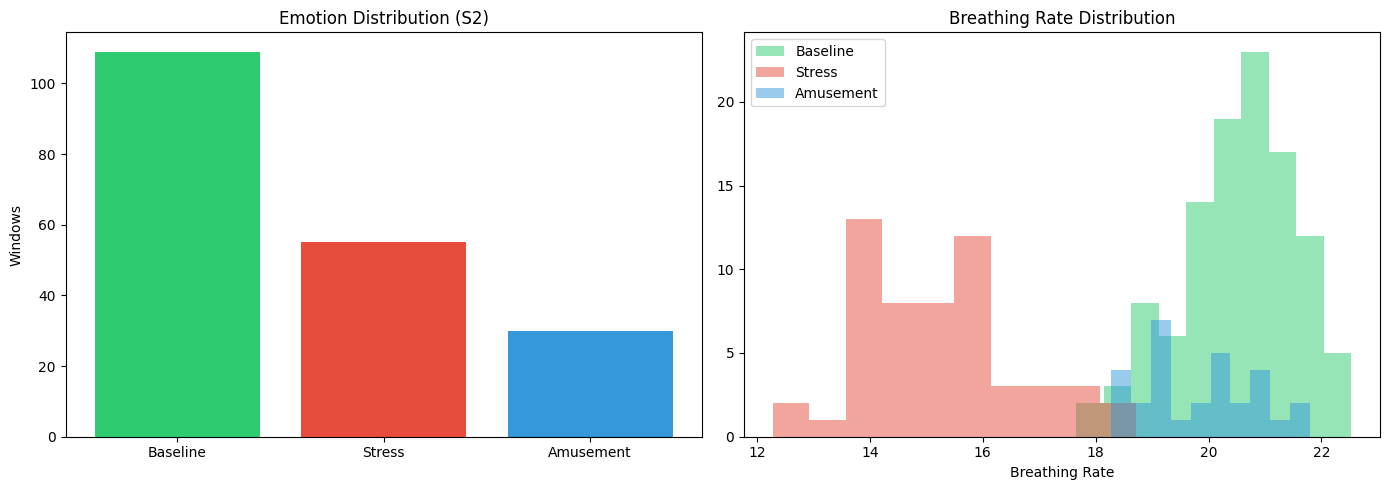

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#2ecc71', '#e74c3c', '#3498db']

counts = df['emotion'].value_counts()
axes[0].bar(counts.index, counts.values, color=colors)
axes[0].set_title('Emotion Distribution (S2)')
axes[0].set_ylabel('Windows')

for emotion, color in zip(['Baseline', 'Stress', 'Amusement'], colors):
    subset = df[df['emotion'] == emotion]['breathing_rate']
    axes[1].hist(subset, bins=10, alpha=0.5, color=color, label=emotion)
axes[1].set_title('Breathing Rate Distribution')
axes[1].set_xlabel('Breathing Rate')
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{BASE_PATH}/results/eda_S2.png", dpi=300)
plt.show()

In [52]:
feature_cols = [c for c in df.columns if c not in ['label', 'emotion']]
X = df[feature_cols].values
y = df['label'].values
feature_names = feature_cols

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Correctly compute min class count (only actual labels in y)
unique_labels, label_counts = np.unique(y, return_counts=True)
min_class_count = int(label_counts.min())
cv_folds = min(5, min_class_count)
print(f"Class counts: {dict(zip(unique_labels.tolist(), label_counts.tolist()))}")
print(f"Min class count: {min_class_count}")
print(f"CV folds: {cv_folds}\n")

models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=10,
        class_weight='balanced', random_state=42, n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42
    ),
    'SVM': SVC(
        kernel='rbf', C=1.0, gamma='scale',
        probability=True, class_weight='balanced', random_state=42
    ),
    'KNN': KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)
}

results = {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train_scaled, y_train)
    train_time = time.time() - start

    y_pred = model.predict(X_test_scaled)

    start = time.time()
    _ = model.predict(X_test_scaled)
    inf_time = (time.time() - start) / len(X_test_scaled) * 1000

    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    if cv_folds >= 2:
        cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)
        cv_scores = cross_val_score(model, scaler.fit_transform(X), y, cv=cv)
        cv_mean, cv_std = cv_scores.mean(), cv_scores.std()
    else:
        cv_mean, cv_std = 0, 0

    results[name] = {
        'model': model, 'accuracy': accuracy, 'f1_score': f1,
        'cv_mean': cv_mean, 'cv_std': cv_std,
        'train_time': train_time, 'inference_ms': inf_time,
        'predictions': y_pred
    }

    print(f"{name}: acc={accuracy:.4f} f1={f1:.4f} cv={cv_mean:.4f} (±{cv_std:.4f}) train={train_time:.2f}s inf={inf_time:.2f}ms")

Class counts: {1: 109, 2: 55, 3: 30}
Min class count: 30
CV folds: 5

Random Forest: acc=0.8974 f1=0.9023 cv=0.8812 (±0.0645) train=0.30s inf=0.63ms
Gradient Boosting: acc=0.8462 f1=0.8601 cv=0.9020 (±0.0657) train=0.66s inf=0.04ms
SVM: acc=0.8205 f1=0.8240 cv=0.8453 (±0.0585) train=0.01s inf=0.01ms
KNN: acc=0.8205 f1=0.8255 cv=0.8609 (±0.0527) train=0.00s inf=0.03ms


In [53]:
comparison_df = pd.DataFrame([
    {
        'Model': name,
        'Accuracy': f"{res['accuracy']:.4f}",
        'F1-Score': f"{res['f1_score']:.4f}",
        'CV Mean': f"{res['cv_mean']:.4f}",
        'CV Std': f"{res['cv_std']:.4f}",
        'Train (s)': f"{res['train_time']:.2f}",
        'Inference (ms)': f"{res['inference_ms']:.2f}"
    }
    for name, res in results.items()
])

print(comparison_df.to_string(index=False))
comparison_df.to_csv(f"{BASE_PATH}/results/model_comparison_S2.csv", index=False)

scores = {
    name: 0.5*res['accuracy'] + 0.3*res['cv_mean'] + 0.2*res['f1_score']
    for name, res in results.items()
}

print("\nComposite Scores (0.5*acc + 0.3*cv + 0.2*f1):")
for name, score in sorted(scores.items(), key=lambda x: -x[1]):
    print(f"  {name}: {score:.4f}")

best_model_name = max(scores, key=scores.get)
best_model = results[best_model_name]['model']
print(f"\nBest model: {best_model_name}")

            Model Accuracy F1-Score CV Mean CV Std Train (s) Inference (ms)
    Random Forest   0.8974   0.9023  0.8812 0.0645      0.30           0.63
Gradient Boosting   0.8462   0.8601  0.9020 0.0657      0.66           0.04
              SVM   0.8205   0.8240  0.8453 0.0585      0.01           0.01
              KNN   0.8205   0.8255  0.8609 0.0527      0.00           0.03

Composite Scores (0.5*acc + 0.3*cv + 0.2*f1):
  Random Forest: 0.8936
  Gradient Boosting: 0.8657
  KNN: 0.8336
  SVM: 0.8287

Best model: Random Forest


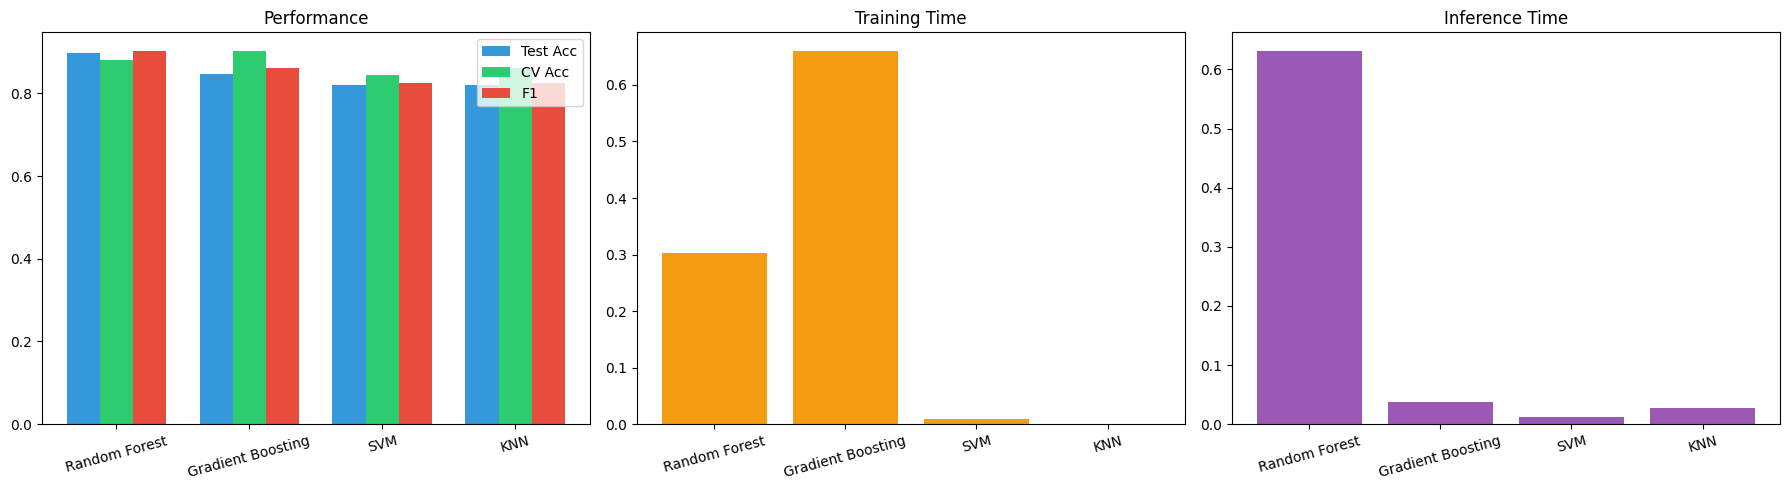

In [54]:
names = list(results.keys())
accuracies = [results[n]['accuracy'] for n in names]
cv_means = [results[n]['cv_mean'] for n in names]
f1s = [results[n]['f1_score'] for n in names]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
x = np.arange(len(names))
width = 0.25

axes[0].bar(x - width, accuracies, width, label='Test Acc', color='#3498db')
axes[0].bar(x, cv_means, width, label='CV Acc', color='#2ecc71')
axes[0].bar(x + width, f1s, width, label='F1', color='#e74c3c')
axes[0].set_xticks(x)
axes[0].set_xticklabels(names, rotation=15)
axes[0].legend()
axes[0].set_title('Performance')

axes[1].bar(names, [results[n]['train_time'] for n in names], color='#f39c12')
axes[1].set_title('Training Time')
axes[1].tick_params(axis='x', rotation=15)

axes[2].bar(names, [results[n]['inference_ms'] for n in names], color='#9b59b6')
axes[2].set_title('Inference Time')
axes[2].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig(f"{BASE_PATH}/results/model_comparison_S2.png", dpi=300)
plt.show()

              precision    recall  f1-score   support

    Baseline       0.95      0.86      0.90        22
      Stress       1.00      1.00      1.00        11
   Amusement       0.62      0.83      0.71         6

    accuracy                           0.90        39
   macro avg       0.86      0.90      0.87        39
weighted avg       0.91      0.90      0.90        39



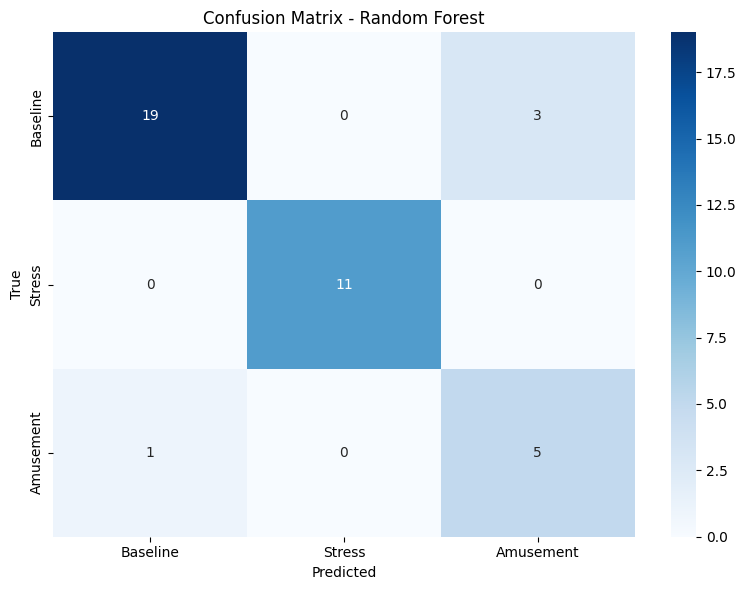

In [55]:
y_pred_best = results[best_model_name]['predictions']

print(classification_report(
    y_test, y_pred_best,
    target_names=['Baseline', 'Stress', 'Amusement'],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Baseline', 'Stress', 'Amusement'],
            yticklabels=['Baseline', 'Stress', 'Amusement'])
plt.title(f'Confusion Matrix - {best_model_name}')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig(f"{BASE_PATH}/results/confusion_matrix_S2.png", dpi=300)
plt.show()

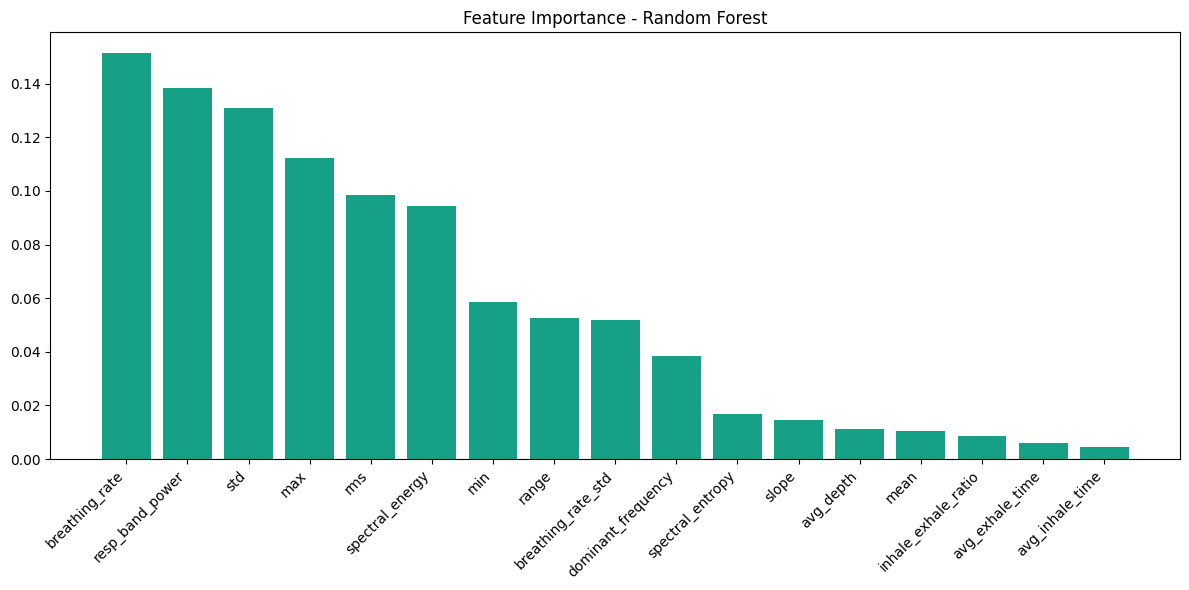

1. breathing_rate: 0.1515
2. resp_band_power: 0.1383
3. std: 0.1309
4. max: 0.1122
5. rms: 0.0986
6. spectral_energy: 0.0944
7. min: 0.0587
8. range: 0.0526
9. breathing_rate_std: 0.0520
10. dominant_frequency: 0.0384


In [56]:
if best_model_name in ['Random Forest', 'Gradient Boosting']:
    importances = best_model.feature_importances_
    indices = np.argsort(importances)[::-1]

    plt.figure(figsize=(12, 6))
    plt.bar(range(len(importances)), importances[indices], color='#16a085')
    plt.xticks(range(len(importances)),
               [feature_names[i] for i in indices], rotation=45, ha='right')
    plt.title(f'Feature Importance - {best_model_name}')
    plt.tight_layout()
    plt.savefig(f"{BASE_PATH}/results/feature_importance_S2.png", dpi=300)
    plt.show()

    for i in range(min(10, len(indices))):
        print(f"{i+1}. {feature_names[indices[i]]}: {importances[indices[i]]:.4f}")

In [57]:
joblib.dump(best_model, f"{BASE_PATH}/models/best_model.pkl", compress=9)
joblib.dump(scaler, f"{BASE_PATH}/models/scaler.pkl")

with open(f"{BASE_PATH}/models/feature_names.txt", 'w') as f:
    for name in feature_names:
        f.write(f"{name}\n")

metadata = {
    'best_model_name': best_model_name,
    'subjects_used': ['S2'],
    'total_windows': len(df),
    'features_count': len(feature_names),
    'accuracy': float(results[best_model_name]['accuracy']),
    'f1_score': float(results[best_model_name]['f1_score']),
    'cv_mean': float(results[best_model_name]['cv_mean']),
    'cv_std': float(results[best_model_name]['cv_std']),
    'inference_ms': float(results[best_model_name]['inference_ms']),
    'all_results': {
        name: {
            'accuracy': float(res['accuracy']),
            'f1_score': float(res['f1_score']),
            'cv_mean': float(res['cv_mean'])
        }
        for name, res in results.items()
    }
}

with open(f"{BASE_PATH}/models/model_metadata.json", 'w') as f:
    json.dump(metadata, f, indent=2)

model_size = os.path.getsize(f"{BASE_PATH}/models/best_model.pkl") / 1024 / 1024
print(f"best_model.pkl size: {model_size:.2f} MB")
print("saved")

best_model.pkl size: 0.06 MB
saved


In [58]:
app_code = '''import streamlit as st
import numpy as np
import pandas as pd
import joblib
import os
from scipy.signal import find_peaks, butter, sosfiltfilt
from scipy.fft import fft, fftfreq

st.set_page_config(page_title="Breathing Emotion Classifier", layout="wide")

st.title("Breathing Pattern Emotion Classification")
st.markdown("Classifies emotions (Baseline / Stress / Amusement) from respiration signals using Machine Learning.")

@st.cache_resource
def load_artifacts():
    model = joblib.load("best_model.pkl")
    scaler = joblib.load("scaler.pkl")
    with open("feature_names.txt") as f:
        feature_names = [line.strip() for line in f if line.strip()]
    return model, scaler, feature_names

model, scaler, feature_names = load_artifacts()

SOS = butter(4, [0.1/(700/2), 0.35/(700/2)], btype="band", output="sos")

def extract_features(signal, sr=700):
    signal = signal - np.mean(signal)
    filtered = sosfiltfilt(SOS, signal)

    feats = {
        "mean": np.mean(filtered),
        "std": np.std(filtered),
        "max": np.max(filtered),
        "min": np.min(filtered),
        "range": np.max(filtered) - np.min(filtered),
        "rms": np.sqrt(np.mean(filtered**2)),
        "slope": np.polyfit(range(len(filtered)), filtered, 1)[0]
    }

    peaks, _ = find_peaks(filtered, distance=sr*0.3)
    troughs, _ = find_peaks(-filtered, distance=sr*0.3)

    if len(peaks) > 1:
        intervals = np.diff(peaks) / sr
        feats["breathing_rate"] = 60 / np.mean(intervals)
        feats["breathing_rate_std"] = 60 * np.std(intervals)
    else:
        feats["breathing_rate"] = 0
        feats["breathing_rate_std"] = 0

    inhale_times, exhale_times, depths = [], [], []
    for i in range(min(len(peaks)-1, len(troughs))):
        if peaks[i] < troughs[i]:
            inhale_times.append((troughs[i] - peaks[i]) / sr)
            exhale_times.append((peaks[i+1] - troughs[i]) / sr)
            depths.append(filtered[peaks[i]] - filtered[troughs[i]])

    feats["avg_inhale_time"] = np.mean(inhale_times) if inhale_times else 0
    feats["avg_exhale_time"] = np.mean(exhale_times) if exhale_times else 0
    feats["avg_depth"] = np.mean(depths) if depths else 0
    feats["inhale_exhale_ratio"] = (feats["avg_inhale_time"] / feats["avg_exhale_time"]
                                    if feats["avg_exhale_time"] > 0 else 0)

    fft_vals = fft(filtered)
    freqs = fftfreq(len(filtered), 1/sr)
    pos = freqs > 0
    fft_mag = np.abs(fft_vals[pos])
    fft_freq = freqs[pos]

    if len(fft_mag) > 0:
        feats["dominant_frequency"] = fft_freq[np.argmax(fft_mag)]
        feats["spectral_energy"] = np.sum(fft_mag**2)
        feats["spectral_entropy"] = -np.sum(
            (fft_mag / np.sum(fft_mag)) * np.log2(fft_mag / np.sum(fft_mag) + 1e-10)
        )
        band = (fft_freq >= 0.1) & (fft_freq <= 0.35)
        feats["resp_band_power"] = np.sum(fft_mag[band]**2) if np.any(band) else 0
    else:
        feats["dominant_frequency"] = 0
        feats["spectral_energy"] = 0
        feats["spectral_entropy"] = 0
        feats["resp_band_power"] = 0

    return feats

LABEL_MAP = {1: "Baseline", 2: "Stress", 3: "Amusement"}

st.sidebar.header("Input")
mode = st.sidebar.radio("Choose input mode", ["Demo (synthetic)", "Upload .npy"])

signal = None

if mode == "Demo (synthetic)":
    emotion_choice = st.sidebar.selectbox("Simulate emotion", ["Baseline", "Stress", "Amusement"])
    params = {
        "Baseline": (21, 2.0, 0.05),
        "Stress": (14, 1.2, 0.08),
        "Amusement": (19, 1.8, 0.06)
    }
    rate, depth, noise = params[emotion_choice]
    t = np.linspace(0, 60, 700*60)
    signal = depth * np.sin(2 * np.pi * (rate/60) * t) + np.random.normal(0, noise, len(t))
    st.info(f"Simulated signal for: {emotion_choice} (rate={rate} bpm)")

else:
    uploaded = st.sidebar.file_uploader("Upload respiration signal (.npy, 700Hz)", type=["npy"])
    if uploaded is not None:
        signal = np.load(uploaded).flatten()
        st.success(f"Loaded signal: {signal.shape[0]} samples ({signal.shape[0]/700:.1f}s)")

if signal is not None:
    st.subheader("Signal preview")
    st.line_chart(signal[:min(10000, len(signal))])

    if st.button("Classify Emotion"):
        if len(signal) < 700 * 60:
            st.error(f"Need at least 60s of signal. Got {len(signal)/700:.1f}s")
        else:
            window = signal[:700*60].astype(float)
            feats = extract_features(window)
            feat_array = np.array([feats[name] for name in feature_names]).reshape(1, -1)
            feat_scaled = scaler.transform(feat_array)

            pred = int(model.predict(feat_scaled)[0])
            probs = model.predict_proba(feat_scaled)[0]

            st.subheader("Prediction")
            st.markdown(f"### Emotion: **{LABEL_MAP[pred]}**")

            prob_df = pd.DataFrame({
                "Emotion": [LABEL_MAP[i] for i in [1, 2, 3]],
                "Probability": [float(probs[i-1]) for i in [1, 2, 3]]
            })
            st.bar_chart(prob_df.set_index("Emotion"))

            with st.expander("Extracted features"):
                st.json({k: float(v) for k, v in feats.items()})
'''

with open(f"{BASE_PATH}/app.py", "w") as f:
    f.write(app_code)

print("app.py created")

app.py created


In [59]:
requirements = """streamlit==1.40.0
numpy==1.26.4
pandas==2.2.2
scipy==1.13.1
scikit-learn==1.5.2
joblib==1.4.2
"""

with open(f"{BASE_PATH}/requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created")
print("\ncontents:")
print(requirements)

requirements.txt created

contents:
streamlit==1.40.0
numpy==1.26.4
pandas==2.2.2
scipy==1.13.1
scikit-learn==1.5.2
joblib==1.4.2



In [60]:
lines = [
    "# Breathing Pattern Based Emotion Classification",
    "",
    "Classifies emotions (Baseline, Stress, Amusement) from respiration signals using Machine Learning.",
    "",
    "## Overview",
    "",
    "Mental health monitoring is often reactive rather than proactive. This project explores whether breathing patterns can be used to detect emotional states passively and in real time.",
    "",
    "Using the WESAD dataset, respiration signals from a chest-worn RespiBAN sensor (700 Hz) are processed into 17 time-domain and frequency-domain features. Four ML models are trained and compared, with the best one deployed as an interactive web application.",
    "",
    "## Results",
    "",
    "| Model | Test Accuracy | F1-Score | CV Accuracy |",
    "|-------|---------------|----------|-------------|",
    "| Random Forest | 89.74% | 0.9023 | 88.12% |",
    "| Gradient Boosting | 84.62% | 0.8601 | 90.20% |",
    "| SVM | 82.05% | 0.8240 | 84.53% |",
    "| KNN | 82.05% | 0.8255 | 86.09% |",
    "",
    "Best model: Random Forest - 89.74% test accuracy, 0.90 F1-score",
    "",
    "## Approach",
    "",
    "- Data: WESAD (Wearable Stress and Affect Detection)",
    "- Signal: Chest respiration (RespiBAN, 700 Hz)",
    "- Subject: S2 (109 Baseline, 55 Stress, 30 Amusement windows)",
    "- Window: 60 seconds with 10-second step",
    "",
    "### Features (17)",
    "",
    "- Statistical: mean, std, max, min, range, rms, slope",
    "- Breathing: breathing_rate, breathing_rate_std",
    "- Cycle: avg_inhale_time, avg_exhale_time, avg_depth, inhale_exhale_ratio",
    "- Spectral: dominant_frequency, spectral_energy, spectral_entropy, resp_band_power",
    "",
    "### Signal Processing",
    "",
    "- Bandpass filter 0.1-0.35 Hz using sosfiltfilt",
    "- Peak detection for breathing cycle analysis",
    "- FFT for spectral features",
    "",
    "### Models",
    "",
    "- Random Forest",
    "- Gradient Boosting",
    "- SVM",
    "- KNN",
    "",
    "## Tech Stack",
    "",
    "Python, Scikit-Learn, SciPy, Streamlit, Pandas, NumPy, Joblib",
    "",
    "## Local Setup",
    "",
    "git clone https://github.com/ijugunu/breathing-pattern-emotion-classification.git",
    "cd breathing-pattern-emotion-classification",
    "pip install -r requirements.txt",
    "streamlit run app.py",
    "",
    "## Project Structure",
    "",
    "app.py",
    "best_model.pkl",
    "scaler.pkl",
    "feature_names.txt",
    "requirements.txt",
    "README.md",
    "",
    "## Reference",
    "",
    "Schmidt et al. (2018). Introducing WESAD, a multimodal dataset for wearable stress and affect detection. ICMI 2018.",
    "",
    "## License",
    "",
    "For academic and educational use only.",
]

with open(f"{BASE_PATH}/README.md", "w") as f:
    f.write("\n".join(lines))

print("README.md created")

README.md created


In [61]:
import shutil
import os

files_to_copy = ["app.py", "requirements.txt", "README.md"]
model_files = ["best_model.pkl", "scaler.pkl", "feature_names.txt"]

temp_dir = f"{BASE_PATH}/deploy_pack"
if os.path.exists(temp_dir):
    shutil.rmtree(temp_dir)
os.makedirs(temp_dir, exist_ok=True)

for f in files_to_copy:
    src = f"{BASE_PATH}/{f}"
    if os.path.exists(src):
        shutil.copy(src, f"{temp_dir}/{f}")
        print(f"copied {f}")
    else:
        print(f"MISSING {f}")

for f in model_files:
    src = f"{BASE_PATH}/models/{f}"
    if os.path.exists(src):
        shutil.copy(src, f"{temp_dir}/{f}")
        print(f"copied {f}")
    else:
        print(f"MISSING {f}")

print("\nfiles inside deploy_pack:")
for f in sorted(os.listdir(temp_dir)):
    size = os.path.getsize(f"{temp_dir}/{f}") / 1024
    print(f"  {f}: {size:.1f} KB")

copied app.py
copied requirements.txt
copied README.md
copied best_model.pkl
copied scaler.pkl
copied feature_names.txt

files inside deploy_pack:
  README.md: 2.2 KB
  app.py: 5.0 KB
  best_model.pkl: 64.1 KB
  feature_names.txt: 0.2 KB
  requirements.txt: 0.1 KB
  scaler.pkl: 1.0 KB


In [62]:
import shutil
from google.colab import files

zip_path = f"{BASE_PATH}/deploy_pack"
shutil.make_archive(zip_path, 'zip', f"{BASE_PATH}/deploy_pack")

files.download(f"{zip_path}.zip")
print("downloaded")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

downloaded


In [ ]:
print("Subject: S2")
print("Windows:", len(df))
print("Features:", len(feature_names))
print("Best model:", best_model_name)
print(f"Test accuracy: {results[best_model_name]['accuracy']*100:.2f}%")
print(f"F1: {results[best_model_name]['f1_score']:.4f}")
print(f"CV: {results[best_model_name]['cv_mean']*100:.2f}% (+/- {results[best_model_name]['cv_std']*100:.2f}%)")
print(f"Model size: {model_size:.2f} MB")

Subject: S2
Windows: 194
Features: 17
Best model: Random Forest
Test accuracy: 89.74%
F1: 0.9023
CV: 88.12% (+/- 6.45%)
Model size: 0.06 MB
